# Bleed-through detection before classifier integration

**Joeal branch · experiment · 11 November 2026**

Goal: identify pages with strong, subtle, or no visible bleed-through and route positive pages through **our existing background normalisation → Otsu → edge gate** method. Nothing here changes Sam's classifier.

This notebook compares three interpretable detector candidates: intermediate-tone area, intermediate-tone components away from foreground ink, and that component evidence with relative edge strength. It separately measures restoration quality against DIBCO foreground ground truth. A detection score is **not** a probability.

**Run all cells from the repository root or `joeal_notebooks/`.** Requires Python 3.10+, NumPy, OpenCV, pandas, matplotlib, scikit-image and IPython. The notebook is self-contained; it does not execute another notebook. Input paths are relative to this repository. Results go to `joeal_data/bleedthrough_detection/results/`.

## 1. Documents, labels and evidence

Nine original DIBCO scans are already in `joeal_data/`. Their foreground masks support restoration scoring; they do **not** identify bleed-through pixels. Severity labels below are provisional visual assessments, recorded before detector results, not official DIBCO annotations. The contact sheets and overlays make them reviewable.

No-visible-bleed controls: two photographs of the same printed page from the existing text-cleanup assignment, plus scikit-image's scanned `page` sample. The photographs have blur and uneven lighting, making them useful confounders, but count as **one source group**. No clean historical handwriting source has yet been established. Consequently the real set cannot establish general accuracy or exclude learning the printed/handwritten distinction.

Sources: [H-DIBCO 2010 resources, including DIBCO 2009 handwriting](https://users.iit.demokritos.gr/~bgat/H-DIBCO2010/resources.html), [H-DIBCO 2014](https://vc.ee.duth.gr/h-dibco2014/), [scikit-image scanned page](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.page). Existing DIBCO files are reused, not re-downloaded. Local photographs retain their existing provenance; no redistribution licence is asserted.

Research motivation: foreground, bleed-through and paper are commonly separated as three components; bleed-through is often lighter/smoother than foreground. Our proposed threshold/component detector is an experiment, not a reproduction of the paper: [Non-Local Sparse Image Inpainting for Document Bleed-Through Removal](https://www.mdpi.com/2313-433X/4/5/68).

{'python': '3.12.14', 'opencv': '5.0.0', 'numpy': '2.5.3', 'skimage': '0.26.0'}


,name,severity,group,note
0,dibco2009/H02,significant,dibco2009,dense ghost lines below the front-side writing
1,dibco2009/H03,significant,dibco2009,large pale ghost strokes between the dark words
2,hdibco2010/H05,significant,hdibco2010,ghost lines interleaved with front-side handwr...
3,hdibco2014/H01,subtle,hdibco2014,faint ghost strokes between foreground lines
4,hdibco2014/H02,subtle,hdibco2014,faint background writing; low-contrast foregro...
5,hdibco2014/H07,significant,hdibco2014,visible background writing across the crop
6,hdibco2014/H08,subtle,hdibco2014,pale ghost text around the foreground block
7,hdibco2014/H09,significant,hdibco2014,visible ghost strokes between and under foregr...
8,hdibco2014/H10,significant,hdibco2014,visible interleaved ghost writing
9,photo_15_92,none,same_printed_page,no visible ghost writing; blur and lighting


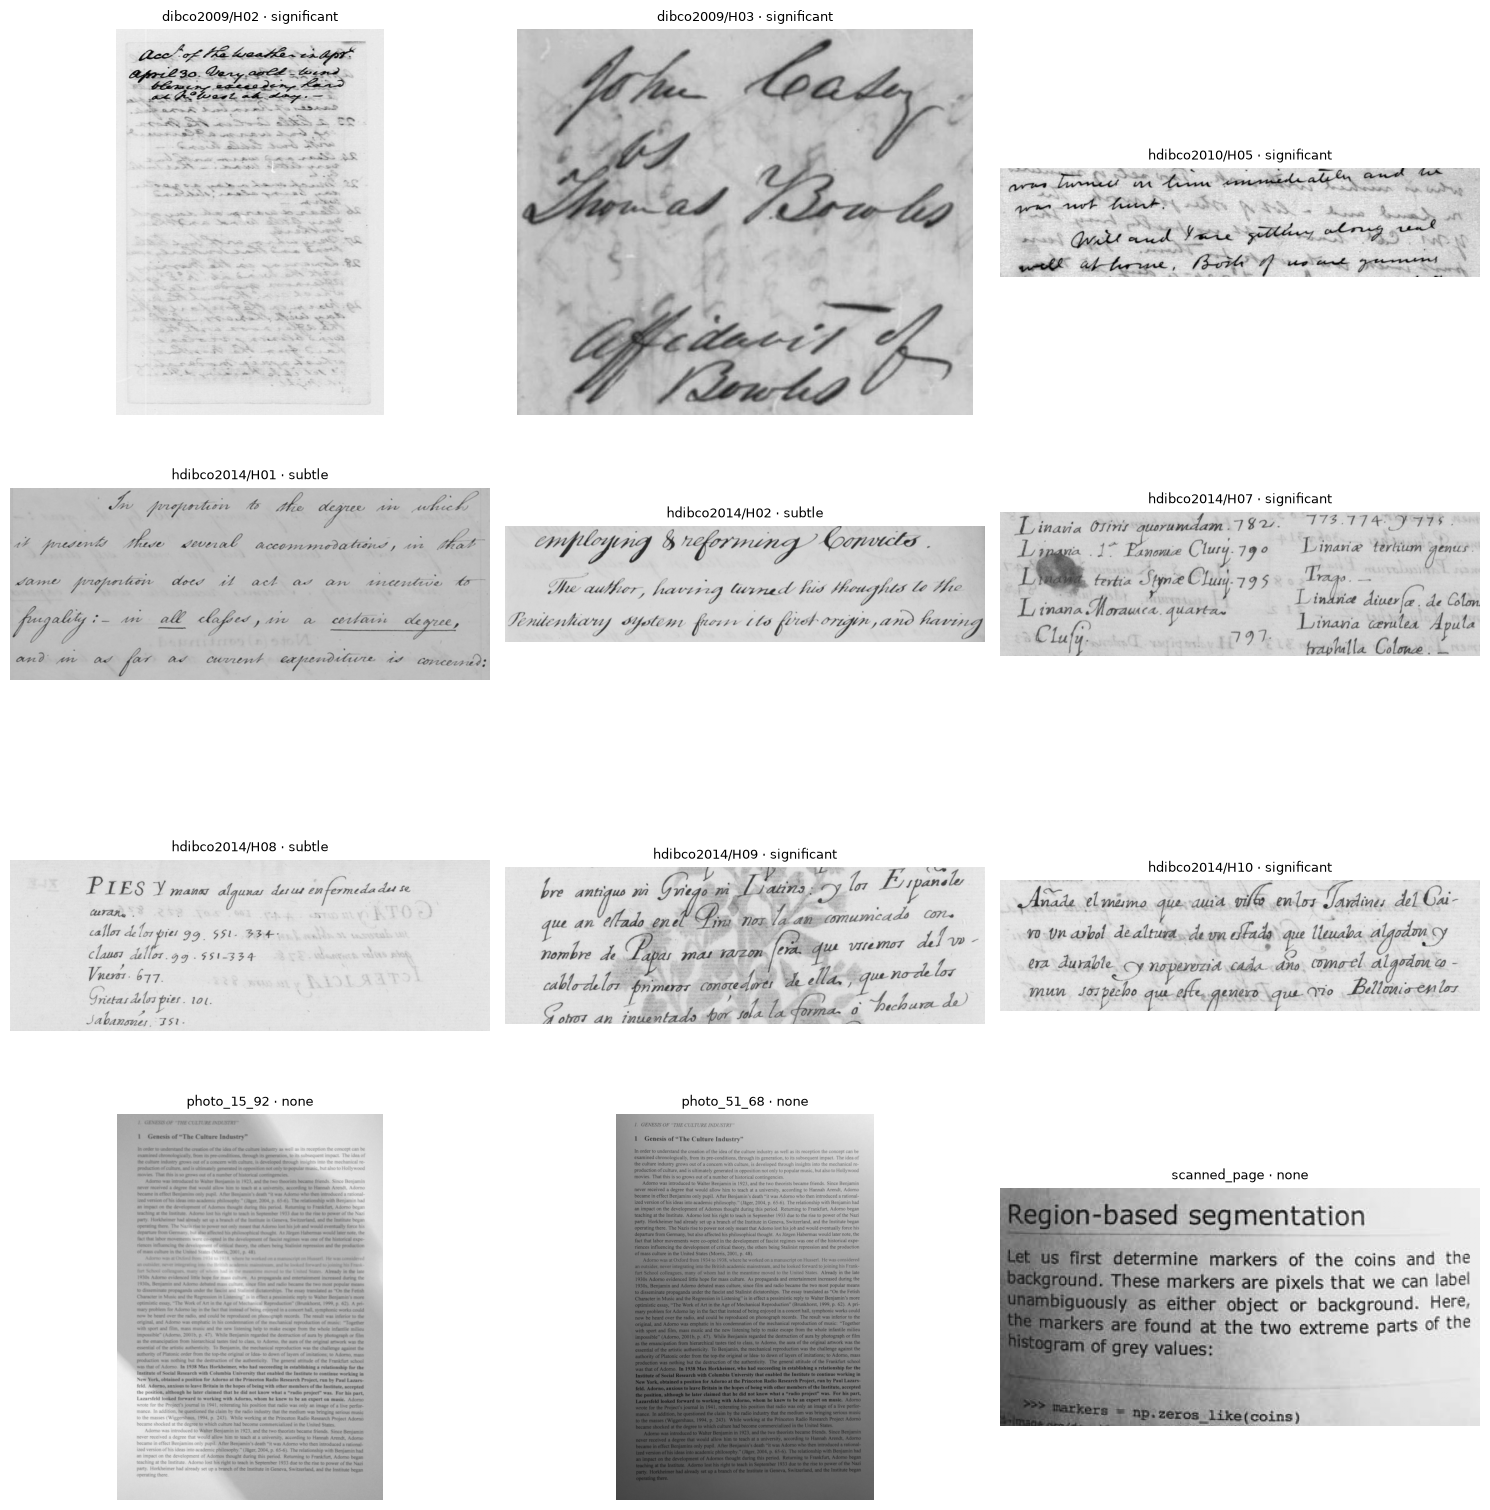

In [1]:
from pathlib import Path
import json, platform, time, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from skimage import data as skdata
from skimage.filters import threshold_otsu, threshold_multiotsu
from skimage.morphology import skeletonize, remove_small_objects
import skimage

ROOT = next(p.resolve() for p in (Path('.'), Path('..')) if (p/'joeal_data').is_dir())
BASE = ROOT/'joeal_data/bleedthrough_detection'
OUT = BASE/'results'
OUT.mkdir(parents=True, exist_ok=True)
VERSIONS = dict(python=platform.python_version(), opencv=cv2.__version__, numpy=np.__version__, skimage=skimage.__version__)
print(VERSIONS)
cv2.imwrite(str(BASE/'inputs/skimage_page.png'), skdata.page())

specs = [
 ('dibco2009/H02', 'significant', 'dense ghost lines below the front-side writing', 'dibco2009'),
 ('dibco2009/H03', 'significant', 'large pale ghost strokes between the dark words', 'dibco2009'),
 ('hdibco2010/H05', 'significant', 'ghost lines interleaved with front-side handwriting', 'hdibco2010'),
 ('hdibco2014/H01', 'subtle', 'faint ghost strokes between foreground lines', 'hdibco2014'),
 ('hdibco2014/H02', 'subtle', 'faint background writing; low-contrast foreground is a confounder', 'hdibco2014'),
 ('hdibco2014/H07', 'significant', 'visible background writing across the crop', 'hdibco2014'),
 ('hdibco2014/H08', 'subtle', 'pale ghost text around the foreground block', 'hdibco2014'),
 ('hdibco2014/H09', 'significant', 'visible ghost strokes between and under foreground lines', 'hdibco2014'),
 ('hdibco2014/H10', 'significant', 'visible interleaved ghost writing', 'hdibco2014'),
]
manifest = []
for name, severity, note, group in specs:
    dataset, stem = name.split('/')
    manifest.append(dict(name=name, severity=severity, group=group, note=note,
       image=f'joeal_data/{dataset}/images/{stem}.png', gt=f'joeal_data/{dataset}/gt/{stem}_gt.png',
       provenance='existing DIBCO project data', label_basis='visual provisional'))
for name, filename, group, note in [
 ('photo_15_92','15_92.png','same_printed_page','no visible ghost writing; blur and lighting'),
 ('photo_51_68','51_68.png','same_printed_page','same page as 15_92; lighting and mild blur'),
 ('scanned_page','skimage_page.png','skimage_page','no visible ghost writing; uneven illumination'),
]:
    manifest.append(dict(name=name,severity='none',group=group,note=note,
      image=f'joeal_data/bleedthrough_detection/inputs/{filename}',gt=None,
      provenance='local assignment photograph' if name.startswith('photo') else 'skimage.data.page()',
      label_basis='visual: no visible bleed; no verso evidence'))
manifest = pd.DataFrame(manifest)
manifest.to_csv(OUT/'document_manifest.csv', index=False)
images, truths, skeletons = {}, {}, {}
for row in manifest.itertuples():
    image = cv2.imread(str(ROOT/row.image), cv2.IMREAD_GRAYSCALE)
    if image is None: raise FileNotFoundError(ROOT/row.image)
    images[row.name] = image
    if isinstance(row.gt, str):
        gt = cv2.imread(str(ROOT/row.gt), cv2.IMREAD_GRAYSCALE)
        if gt is None or gt.shape != image.shape: raise ValueError(f'Bad GT: {row.name}')
        truths[row.name] = gt < 128
        skel_path = (ROOT/row.gt).with_name(Path(row.gt).stem.replace('_gt','_skel')+'.png')
        skeletons[row.name] = cv2.imread(str(skel_path),0) < 128 if skel_path.exists() else None
display(manifest[['name','severity','group','note']])

def show_grid(items, path=None, cols=3, max_side=900):
    rows = (len(items)+cols-1)//cols
    fig, axes = plt.subplots(rows,cols,figsize=(5*cols,3.8*rows),squeeze=False)
    for ax in axes.ravel(): ax.axis('off')
    for ax,(title,img) in zip(axes.ravel(),items):
        scale = min(1,max_side/max(img.shape[:2]))
        small = cv2.resize(img,None,fx=scale,fy=scale,interpolation=cv2.INTER_AREA) if scale<1 else img
        ax.imshow(small,cmap='gray',vmin=0,vmax=255)
        ax.set_title(title,fontsize=9)
    fig.tight_layout()
    if path: fig.savefig(path,dpi=110,bbox_inches='tight')
    plt.show(); plt.close(fig)

show_grid([(f'{r.name} · {r.severity}',images[r.name]) for r in manifest.itertuples()], OUT/'real_documents.png')

## 2. Our restoration method, unchanged

Copied from the current local `DIBCO_bleedthrough_eval.ipynb`, cell 7. Parameters remain fixed: closing 31, median 21, specks ≤30 px, Canny 60/150, component edge ratio >0.08. Foreground is `True`. Detection may resize its analysis copy; restoration and GT scoring always use the original resolution.

Compatibility: older scikit-image calls speck removal `min_size`; newer versions call it `max_size`. The wrapper below preserves the same ≤30-pixel removal rule.

In [2]:
def remove_specks(mask, max_size):
    try:
        return remove_small_objects(mask, max_size=max_size)
    except TypeError:
        return remove_small_objects(mask, min_size=max_size+1)

# --- building blocks + our technique ---
PARAMS = dict(
    close_size=31,       # step 1: closing kernel, larger than any stroke width
    median_size=21,      # step 1: smooths the background estimate
    min_speck=30,        # step 2: components of this many pixels or fewer are removed
    canny=(60, 150),     # step 3: Canny thresholds on the original image
    min_edge_ratio=0.08, # step 3: edge pixels / component size needed to count as real ink
)

def bg_normalise(gray, close_size, median_size):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_size, close_size))
    background = cv2.medianBlur(cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se), median_size)
    norm = np.clip(gray.astype(float) / np.maximum(background, 1) * 255, 0, 255).astype(np.uint8)
    return norm, background

def edge_gate(binary, gray, canny, min_edge_ratio):
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), *canny) > 0
    nl, lab = cv2.connectedComponents(binary.astype(np.uint8), connectivity=8)
    edge_cnt = np.bincount(lab[edges], minlength=nl)
    size = np.bincount(lab.ravel(), minlength=nl)
    keep = edge_cnt / np.maximum(size, 1) > min_edge_ratio
    keep[0] = False                                   # label 0 is background
    return keep[lab], edges

def binarize(gray, p=PARAMS):
    norm, background = bg_normalise(gray, p['close_size'], p['median_size'])          # step 1
    t = threshold_otsu(norm)
    thresh = remove_specks(norm < t, p['min_speck'])                  # step 2
    final, edges = edge_gate(thresh, gray, p['canny'], p['min_edge_ratio'])           # step 3
    return final, dict(background=background, normalised=norm, otsu_t=t,
                       thresholded=thresh, edges=edges, removed_by_gate=thresh & ~final)

## 3. Three detector candidates

All detectors use only the input scan. GT is confined to later evaluation. Detection never calls `binarize`, `bg_normalise` or `edge_gate`. A maximum 1,200-pixel analysis side bounds runtime. A broad Gaussian illumination estimate supplies a temporary analysis image; it is not a restored output and never replaces the original scan.

**A — Tone-only baseline.** Three-class Otsu on the detector's illumination-corrected analysis copy: darkest = possible foreground, middle = candidate weak ink, brightest = paper. Measure middle-class area. This deliberately simple baseline exposes false alarms from faint real text and antialiasing.

**B — Components away from dark ink.** Exclude a small neighbourhood around the darkest Otsu class. This is a detector-only reference mask, not the output of our removal method. Keep intermediate components of plausible text size/shape; reject large smooth areas and page-edge strips. Measure their area relative to dark ink.

**C — Components + relative edges.** Weight each candidate component by whether its gradient strength is weaker than the foreground's. This tests the proposed ghost-writing cue; blurred foreground may still fool it. No calibrated probabilities are produced.

Fixed exploratory cutoffs (declared before running results): A ≥1% page area; B ≥0.08 candidate/foreground area; C ≥0.04 weighted candidate/foreground area. Require at least 3 candidate components and ≥0.1% page area for B/C. These are engineering starting values, **not learned or validated thresholds**. The later threshold sweep is descriptive and must not be reported as held-out accuracy.

Sam's stain mask is deliberately **not** used yet: this experiment must first establish whether bleed-through evidence works. A stain-only stress control below reveals the remaining confounder. Broad component rejection is not equivalent to Sam's stain detector.

In [3]:
THRESHOLDS = dict(tone=0.01, components=0.08, edges=0.04)

def bleedthrough_features(image, max_side=1200):
    if image is None or not isinstance(image,np.ndarray) or image.size == 0:
        raise ValueError('Expected a non-empty image')
    if image.dtype != np.uint8: raise ValueError('Expected uint8 input in [0,255]')
    if image.ndim == 2: gray = image
    elif image.ndim == 3 and image.shape[2] == 3: gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    else: raise ValueError('Expected greyscale or BGR image')
    if min(gray.shape)<8: raise ValueError('Image must be at least 8 pixels in each dimension')
    scale = min(1., max_side/max(gray.shape))
    size = (max(8,round(gray.shape[1]*scale)),max(8,round(gray.shape[0]*scale)))
    small_gray = cv2.resize(gray,size,interpolation=cv2.INTER_AREA)
    # Detection-only lighting correction: broad scale preserves character-size marks.
    sigma = max(3.,0.08*min(small_gray.shape))
    illumination = cv2.GaussianBlur(small_gray.astype(np.float32),(0,0),sigma)
    norm = np.clip(small_gray.astype(np.float32)/np.maximum(illumination,1)*230,0,255).astype(np.uint8)
    h,w = norm.shape
    # Constant scans have no credible weak-ink class.
    if np.unique(norm).size >= 3:
        low,high = threshold_multiotsu(norm,classes=3)
        middle = (norm>low)&(norm<high)
        fg = norm<=low
    else:
        low=high=0; middle=np.zeros_like(norm,dtype=bool);fg=np.zeros_like(middle)
    # A fixed analysis-scale separation prevents foreground stroke edges dominating.
    near_fg = cv2.dilate(fg.astype(np.uint8),np.ones((5,5),np.uint8))>0
    raw_candidates = middle & ~near_fg
    n,labels,stats,_ = cv2.connectedComponentsWithStats(raw_candidates.astype(np.uint8),connectivity=8)
    smooth = cv2.GaussianBlur(small_gray,(3,3),0)
    gradient = cv2.magnitude(cv2.Sobel(smooth,cv2.CV_32F,1,0),cv2.Sobel(smooth,cv2.CV_32F,0,1))
    # Compare stroke boundaries, not interiors with zero gradient.
    fg_boundary = cv2.morphologyEx(fg.astype(np.uint8),cv2.MORPH_GRADIENT,np.ones((3,3),np.uint8))>0
    fg_grad = float(np.percentile(gradient[fg_boundary],75)) if fg_boundary.any() else 0.
    kept=[]; weighted_area=0.; details=[]
    for i in range(1,n):
        x,y,bw,bh,area = stats[i]
        extent=area/(bw*bh); aspect=bw/max(bh,1)
        touches=x==0 or y==0 or x+bw==w or y+bh==h
        if area<5 or area>0.01*h*w or not (0.08<aspect<15) or extent<0.08:
            continue
        if touches and (area/max(bw,bh)<3): continue
        sel=labels==i
        comp_grad=float(np.percentile(gradient[sel],75))
        weakness=float(np.clip(1-comp_grad/max(fg_grad,1),0,1))
        kept.append(i); weighted_area+=area*weakness
        details.append(dict(component=i,area=int(area),gradient=comp_grad,weakness=weakness))
    candidates=np.isin(labels,kept)
    area=int(candidates.sum()); fg_area=int(fg.sum())
    credible=fg_area>=0.002*h*w and len(kept)>=3 and area>=0.001*h*w
    scores=dict(tone=float(middle.mean()),components=area/max(fg_area,1),edges=weighted_area/max(fg_area,1))
    flags=dict(tone=scores['tone']>=THRESHOLDS['tone'],
      components=bool(credible and scores['components']>=THRESHOLDS['components']),
      edges=bool(credible and scores['edges']>=THRESHOLDS['edges']))
    return dict(scores=scores,flags=flags,credible=bool(credible),num_components=len(kept),
      candidate_fraction=float(candidates.mean()),foreground_fraction=float(fg.mean()),
      thresholds=(int(low),int(high)),middle=middle,candidates=candidates,
      analysis_gray=small_gray,analysis_normalised=norm,dark_ink_reference=fg,components=details)

def detect_then_restore(image, detector=bleedthrough_features, restorer=binarize):
    """Only a positive detector-C decision authorises restoration.

    A negative result returns the source pixels unchanged and no restored mask.
    'Positive' means the exploratory rule passed, not independently verified truth.
    """
    evidence=detector(image)
    if not evidence['flags']['edges']:
        return dict(detected=False,restoration_applied=False,image=image.copy(),
                    restored_mask=None,evidence=evidence)
    gray=cv2.cvtColor(image,cv2.COLOR_BGR2GRAY) if image.ndim==3 else image
    restored,stages=restorer(gray)
    return dict(detected=True,restoration_applied=True,
                image=np.where(restored,0,255).astype(np.uint8),restored_mask=restored,
                evidence=evidence)

features={}; rows=[]
for r in manifest.itertuples():
    start=time.perf_counter();f=bleedthrough_features(images[r.name]);features[r.name]=f
    row=dict(name=r.name,severity=r.severity,group=r.group,expected=r.severity!='none',
      seconds=time.perf_counter()-start,num_components=f['num_components'],
      candidate_fraction=f['candidate_fraction'],foreground_fraction=f['foreground_fraction'])
    for k in THRESHOLDS: row[k+'_score']=f['scores'][k];row[k+'_detected']=f['flags'][k]
    rows.append(row)
results=pd.DataFrame(rows)
results.to_csv(OUT/'real_detection_scores.csv',index=False)
display(results.round(4))

,name,severity,group,expected,seconds,num_components,candidate_fraction,foreground_fraction,tone_score,tone_detected,components_score,components_detected,edges_score,edges_detected
0,dibco2009/H02,significant,dibco2009,True,0.2183,858,0.1049,0.0194,0.1178,True,5.4127,True,4.4905,True
1,dibco2009/H03,significant,dibco2009,True,0.0199,124,0.0218,0.0694,0.0864,True,0.3144,True,0.2016,True
2,hdibco2010/H05,significant,hdibco2010,True,0.0237,202,0.0790,0.0493,0.1206,True,1.6013,True,1.1708,True
3,hdibco2014/H01,subtle,hdibco2014,True,0.0541,286,0.0102,0.0266,0.0351,True,0.3828,True,0.2135,True
4,hdibco2014/H02,subtle,hdibco2014,True,0.0257,217,0.0112,0.0446,0.0442,True,0.2520,True,0.1627,True
5,hdibco2014/H07,significant,hdibco2014,True,0.0401,301,0.0280,0.0646,0.0797,True,0.4333,True,0.3535,True
6,hdibco2014/H08,subtle,hdibco2014,True,0.0393,200,0.0171,0.0240,0.0319,True,0.7135,True,0.5875,True
7,hdibco2014/H09,significant,hdibco2014,True,0.0656,543,0.0591,0.0792,0.1181,True,0.7459,True,0.6380,True
8,hdibco2014/H10,significant,hdibco2014,True,0.0477,454,0.0295,0.0772,0.0855,True,0.3815,True,0.3006,True
9,photo_15_92,none,same_printed_page,False,0.2287,927,0.0461,0.1411,0.1993,True,0.3269,True,0.2744,True


## 4. Detection results by severity, with false alarms and misses

The table counts provisional visual labels. Both photographs remain visible individually, but are not independent documents. No threshold is selected from these results. Source-group validation is still required on a larger set containing clean handwriting.

,method,severity,n,flagged,correct,mean_score
0,tone,significant,6,6,6,0.1014
1,tone,subtle,3,3,3,0.0371
2,tone,none,3,3,0,0.1209
3,components,significant,6,6,6,1.4815
4,components,subtle,3,3,3,0.4494
5,components,none,3,1,2,0.1532
6,edges,significant,6,6,6,1.1925
7,edges,subtle,3,3,3,0.3212
8,edges,none,3,2,1,0.1143


,method,TP,FN,FP,TN
0,tone,9,0,3,0
1,components,9,0,1,2
2,edges,9,0,2,1


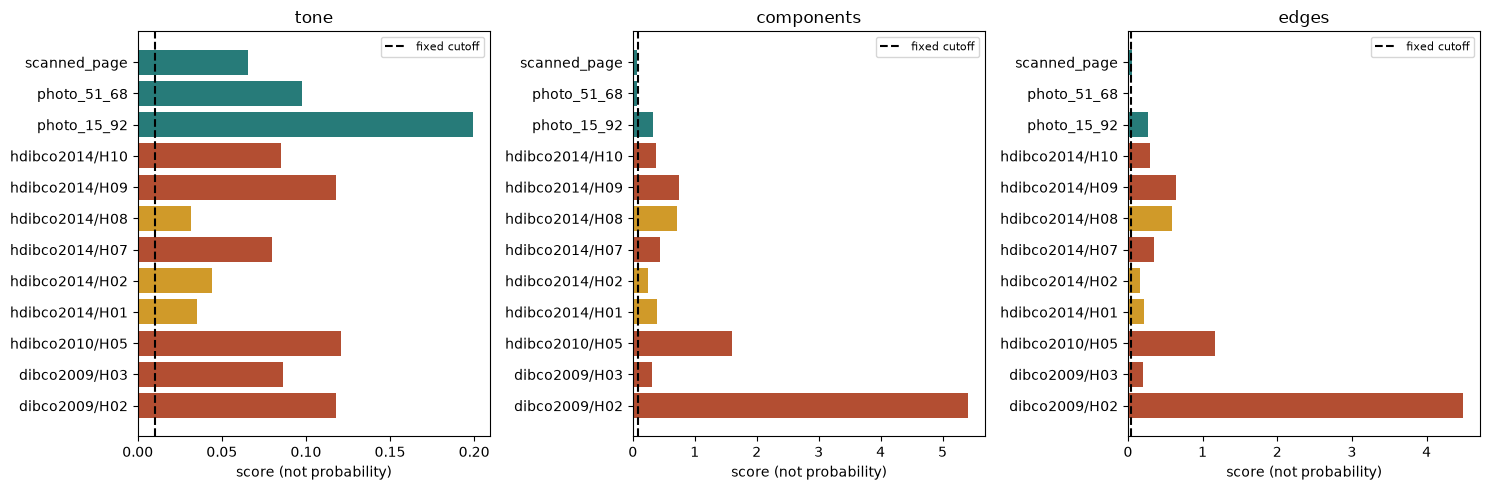

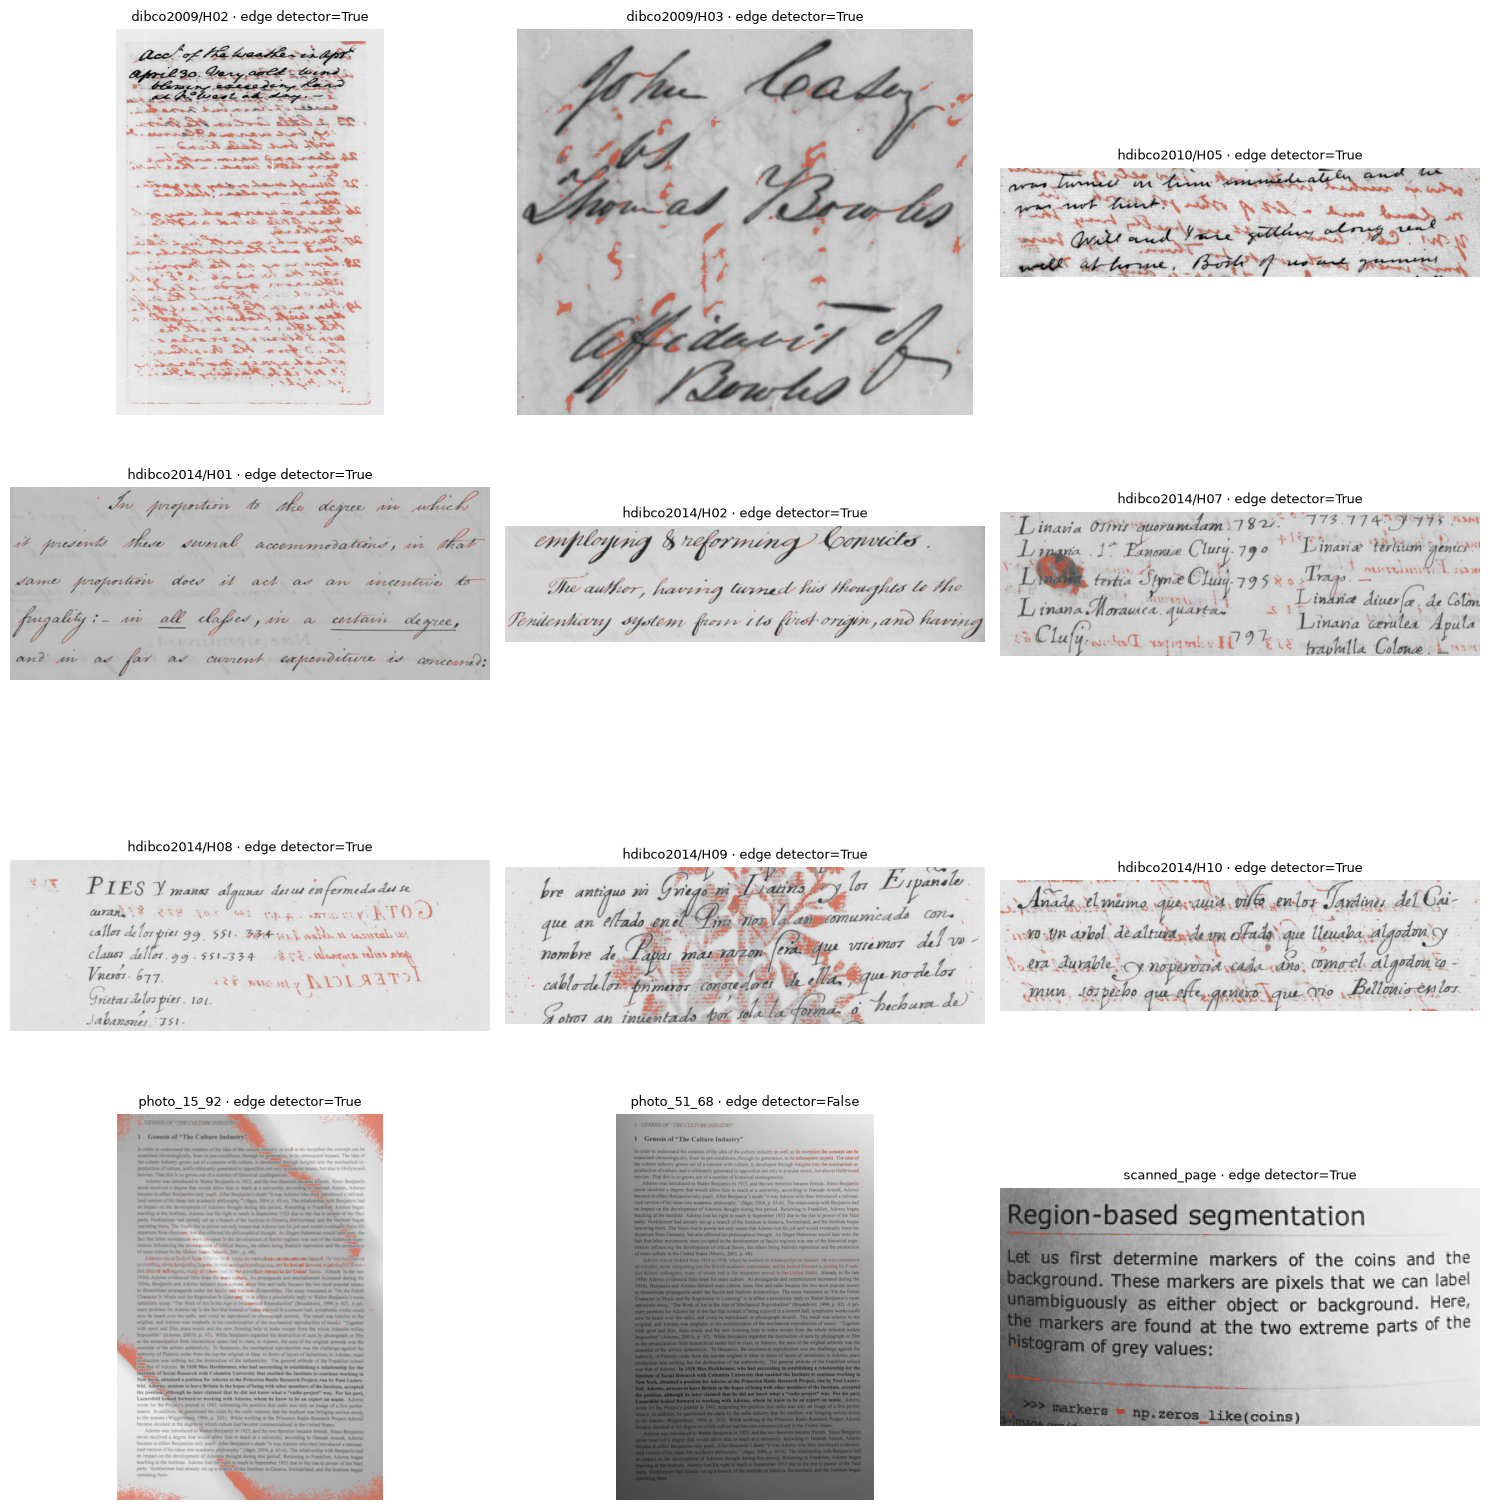

In [4]:
summary=[]
for method in THRESHOLDS:
    for severity,part in results.groupby('severity',sort=False):
        expected=part['expected'].to_numpy();pred=part[method+'_detected'].to_numpy()
        summary.append(dict(method=method,severity=severity,n=len(part),flagged=int(pred.sum()),
          correct=int((pred==expected).sum()),mean_score=part[method+'_score'].mean()))
summary=pd.DataFrame(summary)
display(summary.round(4));summary.to_csv(OUT/'detection_by_severity.csv',index=False)
confusion=[]
for method in THRESHOLDS:
    y=results.expected.to_numpy();p=results[method+'_detected'].to_numpy()
    confusion.append(dict(method=method,TP=int((y&p).sum()),FN=int((y&~p).sum()),
      FP=int((~y&p).sum()),TN=int((~y&~p).sum())))
confusion=pd.DataFrame(confusion)
display(confusion);confusion.to_csv(OUT/'real_confusion_counts.csv',index=False)

fig,axes=plt.subplots(1,3,figsize=(15,5))
colors=results.severity.map(dict(significant='#b34e32',subtle='#d09a29',none='#277b79'))
for ax,method in zip(axes,THRESHOLDS):
    ax.barh(results.name,results[method+'_score'],color=colors)
    ax.axvline(THRESHOLDS[method],color='black',linestyle='--',label='fixed cutoff')
    ax.set_title(method);ax.set_xlabel('score (not probability)');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'detector_scores.png',dpi=120);plt.show();plt.close(fig)

overlays=[]
for r in manifest.itertuples():
    f=features[r.name];rgb=cv2.cvtColor(f['analysis_gray'],cv2.COLOR_GRAY2RGB)
    m=f['candidates'];rgb[m]=(0.45*rgb[m]+0.55*np.array([235,70,35])).astype(np.uint8)
    overlays.append((f"{r.name} · edge detector={f['flags']['edges']}",rgb))
show_grid(overlays,OUT/'candidate_overlays.png')

## 5. Does our restoration help, and does routing preserve that benefit?

Production-style flow: `detect_then_restore()` first runs detection, calls our restoration only on a positive C decision, and otherwise returns the original pixels unchanged. No cleaned foreground mask is available to the detector.

The **separate benchmark** below deliberately applies our method to every page to measure restoration quality. This is not part of detection. For numeric GT evaluation only, an unchanged negative-route greyscale scan is converted using plain Otsu; the routing function itself does not apply that conversion. Compare that score with plain Otsu and always-on restoration to expose missed-detection costs. This is not the final three-method classifier. No restoration scores are invented for negative documents without GT.

F and pseudo-F are percentages (higher better). Pseudo-F uses the official skeleton where supplied, otherwise a computed skeleton. DRD is lower better. These functions match the existing evaluation notebook. A good restoration F-score does not prove correct bleed-through detection, because GT also excludes other background defects.

In [5]:
_i, _j = np.mgrid[-2:3, -2:3]
W_DRD = np.where((_i == 0) & (_j == 0), 0, 1 / np.sqrt(np.maximum(_i**2 + _j**2, 1)))
W_DRD /= W_DRD.sum()

def drd(pred, gt):
    nbr = cv2.filter2D(gt.astype(float), -1, W_DRD, borderType=cv2.BORDER_CONSTANT)
    cost = np.where(pred, 1 - nbr, nbr)          # weighted disagreement with GT neighbours
    total = cost[pred != gt].sum()
    H, W = gt.shape
    blocks = gt[:H // 8 * 8, :W // 8 * 8].reshape(H // 8, 8, W // 8, 8).sum(axis=(1, 3))
    nubn = np.count_nonzero((blocks != 0) & (blocks != 64))
    return total / max(nubn, 1)

def evaluate(pred, gt, skel=None):
    p, g = pred.astype(bool), gt.astype(bool)
    tp = np.count_nonzero(p & g); fp = np.count_nonzero(p & ~g); fn = np.count_nonzero(~p & g)
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    f = 2 * prec * rec / max(prec + rec, 1e-12)
    skel = skeletonize(g) if skel is None else skel
    p_rec = np.count_nonzero(p & skel) / max(np.count_nonzero(skel), 1)
    pf = 2 * prec * p_rec / max(prec + p_rec, 1e-12)
    mse = np.mean(p != g)
    psnr = 10 * np.log10(1 / mse) if mse > 0 else np.inf
    return {'F': 100 * f, 'pF': 100 * pf, 'PSNR': psnr, 'DRD': drd(p, g)}

,name,detected,restoration_applied,unchanged
0,dibco2009/H02,True,True,False
1,dibco2009/H03,True,True,False
2,hdibco2010/H05,True,True,False
3,hdibco2014/H01,True,True,False
4,hdibco2014/H02,True,True,False
5,hdibco2014/H07,True,True,False
6,hdibco2014/H08,True,True,False
7,hdibco2014/H09,True,True,False
8,hdibco2014/H10,True,True,False
9,photo_15_92,True,True,False


method,Detector C routed,"Our method, always",Plain Otsu
name,,,
dibco2009/H02,91.26,91.26,86.45
dibco2009/H03,88.06,88.06,84.52
hdibco2010/H05,93.02,93.02,88.76
hdibco2014/H01,88.76,88.76,88.39
hdibco2014/H02,85.09,85.09,86.20
hdibco2014/H07,91.40,91.40,84.10
hdibco2014/H08,92.77,92.77,92.99
hdibco2014/H09,93.38,93.38,92.20
hdibco2014/H10,92.90,92.90,92.62


,F,pF,PSNR,DRD
method,,,,
Detector C routed,90.739,94.658,19.668,2.566
"Our method, always",90.739,94.658,19.668,2.566
Plain Otsu,88.468,92.237,18.579,3.895


F      pF    DRD
severity    method                                   
significant Detector C routed   91.671  95.402  2.432
            Our method, always  91.671  95.402  2.432
            Plain Otsu          88.106  91.192  4.461
subtle      Detector C routed   88.876  93.170  2.832
            Our method, always  88.876  93.170  2.832
            Plain Otsu          89.191  94.328  2.764

method,gain_ours_vs_otsu,routing_loss_vs_always
name,,
dibco2009/H02,4.807,0.0
dibco2009/H03,3.541,0.0
hdibco2010/H05,4.268,0.0
hdibco2014/H01,0.376,0.0
hdibco2014/H02,-1.109,0.0
hdibco2014/H07,7.299,0.0
hdibco2014/H08,-0.213,0.0
hdibco2014/H09,1.187,0.0
hdibco2014/H10,0.284,0.0


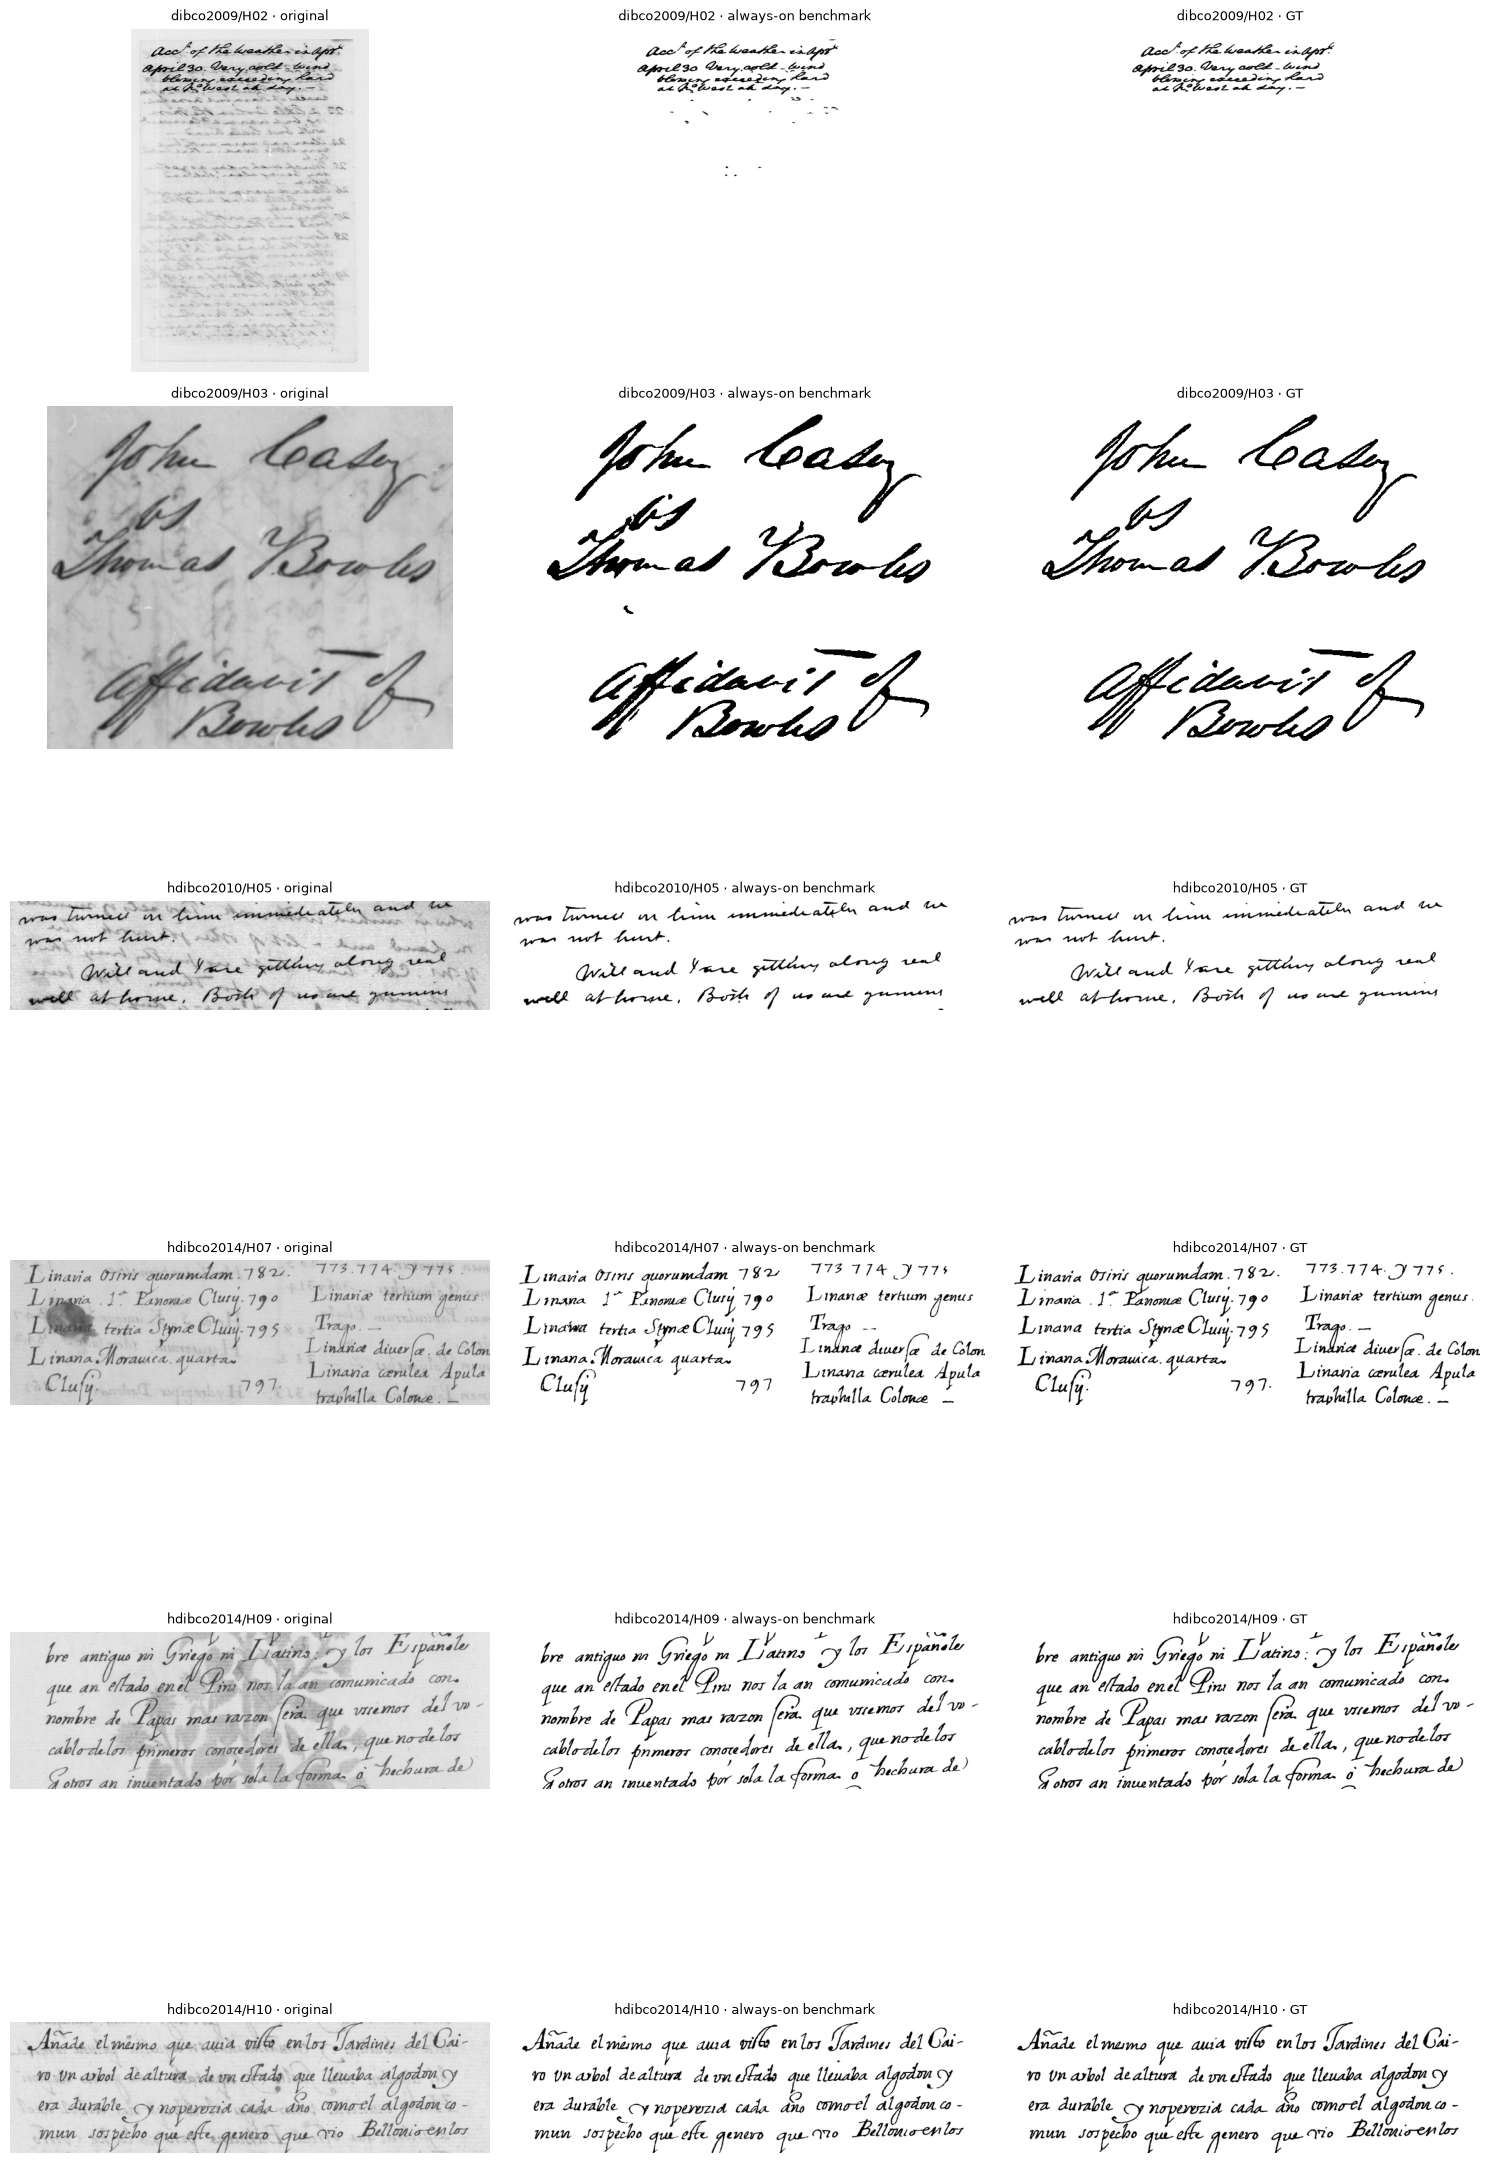

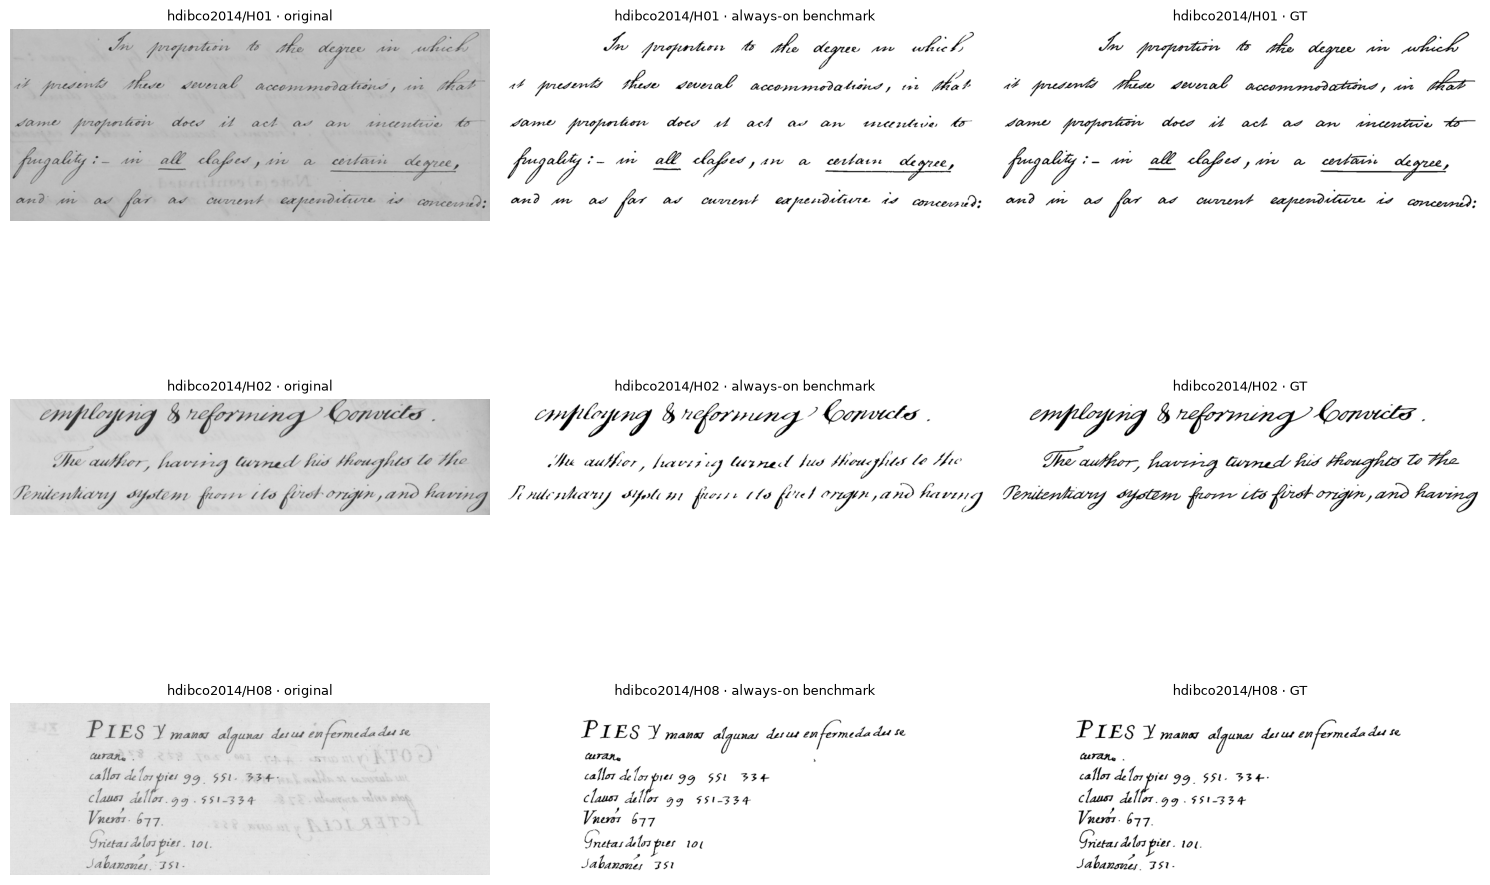

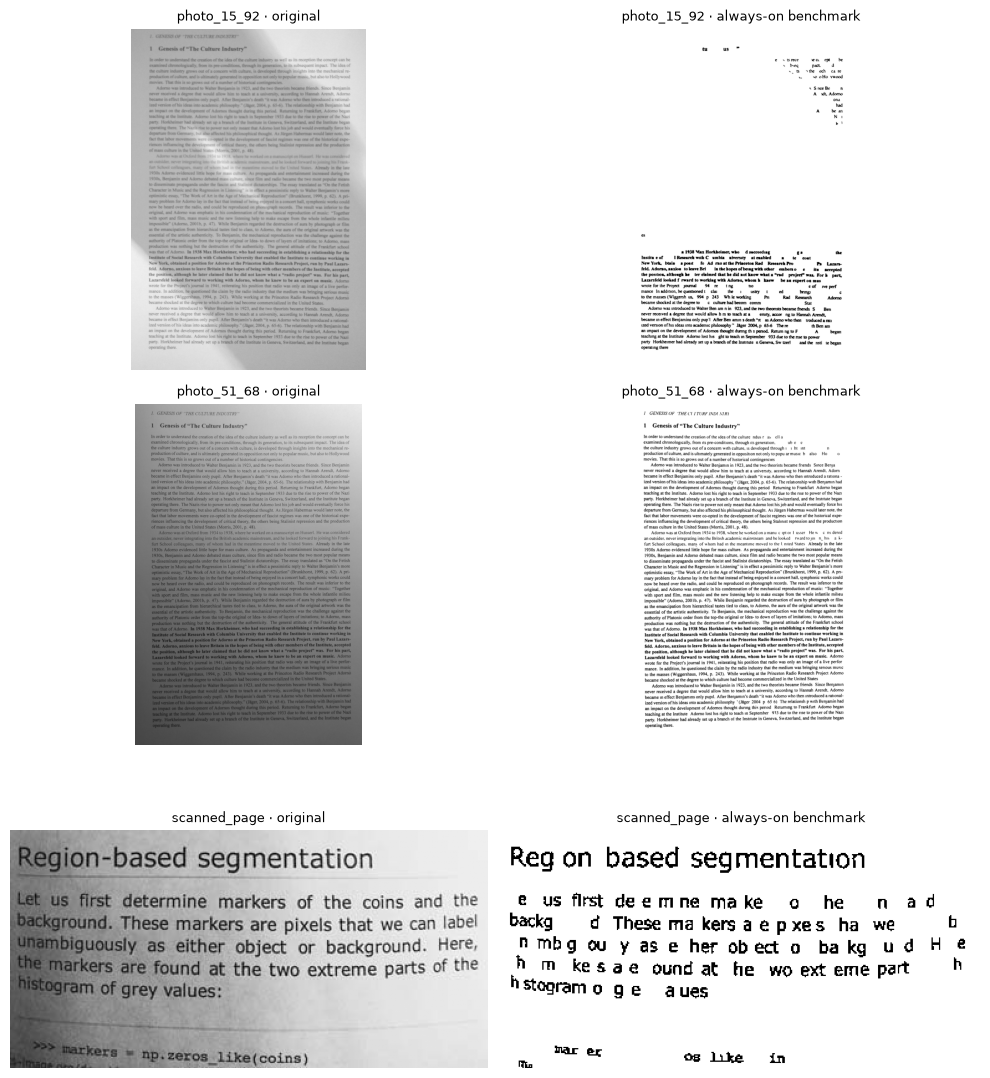

In [6]:
quality=[];benchmark_outputs={};routing_rows=[];routed_outputs={}
for name,img in images.items():
    route=detect_then_restore(img)
    routed_outputs[name]=route
    routing_rows.append(dict(name=name,detected=route['detected'],restoration_applied=route['restoration_applied'],
      unchanged=bool(np.array_equal(img,route['image'])) if not route['detected'] else False))
    # Deliberately separate always-on benchmark; never used by detection.
    benchmark_outputs[name]=binarize(img)[0]
pd.DataFrame(routing_rows).to_csv(OUT/'conditional_routing.csv',index=False)
display(pd.DataFrame(routing_rows))
for name,gt in truths.items():
    img=images[name];f=features[name]
    plain=img<threshold_otsu(img)
    route=routed_outputs[name]
    outputs={'Plain Otsu':plain,'Our method, always':benchmark_outputs[name],
      'Detector C routed':route['restored_mask'] if route['detected'] else plain}
    for method,pred in outputs.items():
        quality.append(dict(name=name,method=method,**evaluate(pred,gt,skeletons[name])))
quality=pd.DataFrame(quality)
quality.to_csv(OUT/'restoration_scores.csv',index=False)
display(quality.pivot(index='name',columns='method',values='F').round(2))
display(quality.groupby('method')[['F','pF','PSNR','DRD']].mean().round(3))
display(quality.merge(manifest[['name','severity']],on='name').groupby(['severity','method'])[['F','pF','DRD']].mean().round(3))
q=quality.pivot(index='name',columns='method',values='F')
q['gain_ours_vs_otsu']=q['Our method, always']-q['Plain Otsu']
q['routing_loss_vs_always']=q['Our method, always']-q['Detector C routed']
display(q[['gain_ours_vs_otsu','routing_loss_vs_always']].round(3))
q.to_csv(OUT/'restoration_gains.csv')
for severity in ['significant','subtle','none']:
    names=manifest.loc[manifest.severity==severity,'name'].tolist()
    panels=[]
    for name in names:
        panels += [(name+' · original',images[name]),
          (name+' · always-on benchmark',np.where(benchmark_outputs[name],0,255).astype(np.uint8))]
        if name in truths: panels += [(name+' · GT',np.where(truths[name],0,255).astype(np.uint8))]
    show_grid(panels,OUT/f'restoration_{severity}.png',cols=3 if severity!='none' else 2)

## 6. Matched controlled test: none, subtle, significant

Real labels are subjective and our negative documents are a different style. To isolate severity, create matched greyscale pages from three existing GT foreground masks. White paper plus dark front ink is overlaid with a horizontally mirrored, shifted and blurred ink pattern, at contrasts 0 (none), 12 (subtle), and 45 (significant). Ground truth does **not** enter detection; it constructs these explicitly synthetic inputs and scores restoration.

This supplies known bleed masks, including faint ghosts that may disappear during normalisation. These controls are not real scans, not an independent benchmark, and are never pooled into the real-document confusion table. Additional no-bleed stress cases use blur, faded foreground, lighting and a broad stain. These test false alarms rather than demonstrate generalisation.

,name,source,severity,kind,expected,tone_score,tone_detected,components_score,components_detected,edges_score,edges_detected,ours_F,ghost_evidence_recall
0,dibco2009/H02 · synthetic none,dibco2009/H02,none,controlled ghost,False,0.8212,True,0.1418,False,0.1418,False,99.7022,NaN
1,dibco2009/H02 · synthetic subtle,dibco2009/H02,subtle,controlled ghost,True,0.8212,True,0.2164,True,0.2134,True,99.7813,0.0666
2,dibco2009/H02 · synthetic significant,dibco2009/H02,significant,controlled ghost,True,0.8222,True,0.9220,True,0.7783,True,99.7635,0.6315
3,dibco2009/H02 · blur only,dibco2009/H02,none,blur only,False,0.8232,True,0.0926,True,0.0873,True,85.7381,NaN
4,dibco2009/H02 · faint text only,dibco2009/H02,none,faint text only,False,0.7875,True,0.0000,False,0.0000,False,99.6914,NaN
5,dibco2009/H02 · lighting only,dibco2009/H02,none,lighting only,False,0.8266,True,0.0003,False,0.0003,False,99.7705,NaN
6,dibco2009/H02 · stain only,dibco2009/H02,none,stain only,False,0.8180,True,0.1401,False,0.1401,False,99.7022,NaN
7,hdibco2014/H01 · synthetic none,hdibco2014/H01,none,controlled ghost,False,0.0237,True,0.0000,False,0.0000,False,99.4321,NaN
8,hdibco2014/H01 · synthetic subtle,hdibco2014/H01,subtle,controlled ghost,True,0.0236,True,0.0000,False,0.0000,False,99.7958,0.0000
9,hdibco2014/H01 · synthetic significant,hdibco2014/H01,significant,controlled ghost,True,0.0756,True,0.8562,True,0.7014,True,99.7852,0.5871


tone_detected  components_detected  \
kind             severity                                          
blur only        none                   1.0                0.333   
controlled ghost none                   1.0                0.000   
                 significant            1.0                1.000   
                 subtle                 1.0                0.667   
faint text only  none                   1.0                0.000   
lighting only    none                   1.0                0.000   
stain only       none                   1.0                0.000   

                              edges_detected  ours_F  
kind             severity                             
blur only        none                  0.333  82.065  
controlled ghost none                  0.000  99.493  
                 significant           1.000  99.713  
                 subtle                0.667  99.645  
faint text only  none                  0.000  99.675  
lighting only    none                  0.000  99.716  
stain only       none                  0.000  99.504

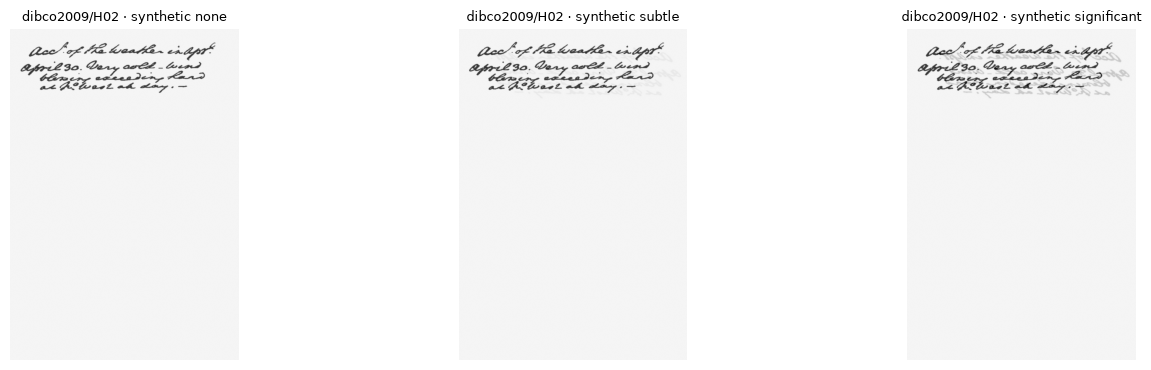

In [7]:
synthetic={}; synthetic_gt={}; synthetic_meta=[]; ghost_masks={}
for name in ['dibco2009/H02','hdibco2014/H01','hdibco2014/H08']:
    gt=truths[name];h,w=gt.shape
    front=cv2.GaussianBlur(gt.astype(np.float32),(0,0),0.55)
    back=cv2.flip(gt.astype(np.float32),1)
    back=cv2.warpAffine(back,np.float32([[1,0,17],[0,1,23]]),(w,h),borderMode=cv2.BORDER_CONSTANT)
    back=cv2.GaussianBlur(back,(0,0),1.0)
    for severity,contrast in [('none',0),('subtle',12),('significant',45)]:
        key=f'{name} · synthetic {severity}'
        synthetic[key]=np.clip(245-190*front-contrast*back,0,255).astype(np.uint8)
        synthetic_gt[key]=gt;ghost_masks[key]=(back>0.15)&~gt if contrast else np.zeros_like(gt)
        synthetic_meta.append(dict(name=key,source=name,severity=severity,kind='controlled ghost'))
    clean=np.clip(245-190*front,0,255).astype(np.uint8)
    yy,xx=np.mgrid[0:h,0:w]
    stain=40*np.exp(-((xx-w*0.7)**2+(yy-h*0.45)**2)/(2*(min(h,w)*0.14)**2))
    stress={
      'blur only':cv2.GaussianBlur(clean,(0,0),2.0),
      'faint text only':np.clip(245-40*front,0,255).astype(np.uint8),
      'lighting only':np.clip(clean.astype(float)*(0.65+0.35*xx/max(w-1,1)),0,255).astype(np.uint8),
      'stain only':np.clip(clean.astype(float)-stain,0,255).astype(np.uint8)}
    for label,img in stress.items():
        key=f'{name} · {label}';synthetic[key]=img;synthetic_gt[key]=gt
        synthetic_meta.append(dict(name=key,source=name,severity='none',kind=label))
syn_rows=[];syn_features={}
for r in synthetic_meta:
    name=r['name'];f=bleedthrough_features(synthetic[name]);syn_features[name]=f
    row=dict(**r,expected=r['severity']!='none')
    for method in THRESHOLDS:
        row[method+'_score']=f['scores'][method];row[method+'_detected']=f['flags'][method]
    # Always-on restoration is a separate evaluation, after detector output exists.
    row['ours_F']=evaluate(binarize(synthetic[name])[0],synthetic_gt[name])['F']
    # Coverage of *known synthetic* ghost pixels by the detector evidence mask.
    if name in ghost_masks and ghost_masks[name].any():
        m=cv2.resize(f['candidates'].astype(np.uint8),synthetic[name].shape[::-1],interpolation=cv2.INTER_NEAREST)>0
        row['ghost_evidence_recall']=float((m&ghost_masks[name]).sum()/ghost_masks[name].sum())
    syn_rows.append(row)
syn_results=pd.DataFrame(syn_rows)
syn_results.to_csv(OUT/'controlled_scores.csv',index=False)
display(syn_results.round(4))
display(syn_results.groupby(['kind','severity'])[[m+'_detected' for m in THRESHOLDS]+['ours_F']].mean().round(3))
matched=[k for k in synthetic if k.startswith('dibco2009/H02') and 'synthetic' in k]
show_grid([(k,synthetic[k]) for k in matched],OUT/'matched_severity.png')

## 7. Threshold sensitivity and robustness

The sweep shows the trade-off on these same exploratory examples. It is not a threshold-selection validation set. Do not choose the best row and report that score as independent performance. Freeze a candidate later, then evaluate on unseen source documents with clean handwriting negatives and mixed stain/bleed cases.

In [8]:
sweep=[]
for method in THRESHOLDS:
    grid=[0.002,0.005,0.01,0.02,0.04] if method=='tone' else [0.01,0.02,0.04,0.08,0.16,0.32]
    for threshold in grid:
        pred=results[method+'_score'].to_numpy()>=threshold
        if method!='tone': pred &= np.array([features[n]['credible'] for n in results.name])
        y=results.expected.to_numpy()
        sweep.append(dict(method=method,threshold=threshold,TP=int((y&pred).sum()),
          FN=int((y&~pred).sum()),FP=int((~y&pred).sum()),TN=int((~y&~pred).sum())))
sweep=pd.DataFrame(sweep);display(sweep);sweep.to_csv(OUT/'threshold_sensitivity.csv',index=False)

checks=[]
for label,img in [('white',np.full((100,100),255,np.uint8)),('black',np.zeros((100,100),np.uint8))]:
    with warnings.catch_warnings(record=True) as caught:
        f=bleedthrough_features(img)
    assert not any(f['flags'].values()),label
    assert all(np.isfinite(v) for v in f['scores'].values()),label
    checks.append(dict(case=label,passed=True,warnings=len(caught)))
g=images['dibco2009/H02'];a=features['dibco2009/H02'];b=bleedthrough_features(cv2.cvtColor(g,cv2.COLOR_GRAY2BGR))
assert a['scores']==b['scores'] and a['flags']==b['flags']
checks.append(dict(case='identical grey and replicated BGR',passed=True,warnings=0))
for label,bad in [('missing',None),('empty',np.zeros((0,0),np.uint8)),('tiny',np.zeros((2,2),np.uint8)),('float',np.zeros((10,10),float))]:
    try: bleedthrough_features(bad)
    except ValueError: checks.append(dict(case=label,passed=True,warnings=0))
    else: raise AssertionError(label)
display(pd.DataFrame(checks))
(OUT/'robustness_checks.json').write_text(json.dumps(checks,indent=2))

# Prove detection cannot secretly invoke any restoration building block.
saved={name:globals()[name] for name in ['binarize','bg_normalise','edge_gate']}
def forbidden(*args,**kwargs): raise AssertionError('Detection called restoration')
try:
    globals().update({name:forbidden for name in saved})
    for img in list(images.values())+list(synthetic.values()): bleedthrough_features(img)
finally:
    globals().update(saved)
checks.append(dict(case='all 33 inputs detect with restoration functions forbidden',passed=True,warnings=0))

# Spy on the real conditional route; there must be exactly one call per positive.
calls=[]
def spy_restore(gray):
    calls.append('restore')
    return binarize(gray)
for name,img in images.items():
    before=img.copy();count=len(calls)
    routed=detect_then_restore(img,restorer=spy_restore)
    assert len(calls)-count==int(routed['detected'])
    assert routed['restoration_applied']==routed['detected']
    assert np.array_equal(img,before),'Input mutated'
    if not routed['detected']:
        assert routed['restored_mask'] is None
        assert np.array_equal(routed['image'],img),'Negative route altered source'
checks.append(dict(case='real routes call restoration only after positive decision; inputs preserved',passed=True,warnings=0))

# Exercise both routing branches independently of real detector outcomes.
events=[]
def forced_detector(flag):
    def detector(image):
        events.append('detect')
        return {'flags':{'edges':flag}}
    return detector
def ordered_restore(gray):
    events.append('restore')
    return np.zeros_like(gray,dtype=bool),{}
for flag in [False,True]:
    events.clear();r=detect_then_restore(g,detector=forced_detector(flag),restorer=ordered_restore)
    assert events==(['detect','restore'] if flag else ['detect'])
checks.append(dict(case='forced positive and negative: detection precedes conditional restoration',passed=True,warnings=0))
display(pd.DataFrame(checks))
(OUT/'robustness_checks.json').write_text(json.dumps(checks,indent=2))

,method,threshold,TP,FN,FP,TN
0,tone,0.002,9,0,3,0
1,tone,0.005,9,0,3,0
2,tone,0.010,9,0,3,0
3,tone,0.020,9,0,3,0
4,tone,0.040,7,2,3,0
5,components,0.010,9,0,3,0
6,components,0.020,9,0,3,0
7,components,0.040,9,0,3,0
8,components,0.080,9,0,1,2
9,components,0.160,9,0,1,2


,case,passed,warnings
0,white,True,0
1,black,True,0
2,identical grey and replicated BGR,True,0
3,missing,True,0
4,empty,True,0
5,tiny,True,0
6,float,True,0


,case,passed,warnings
0,white,True,0
1,black,True,0
2,identical grey and replicated BGR,True,0
3,missing,True,0
4,empty,True,0
5,tiny,True,0
6,float,True,0
7,all 33 inputs detect with restoration function...,True,0
8,real routes call restoration only after positi...,True,0
9,forced positive and negative: detection preced...,True,0


900

## 8. Findings and decision before integration

The summary below is generated from this run. It reports the fixed-threshold results, misses and false alarms rather than assuming the proposed detector works. Inspect the overlays: red marks are **candidate weak-ink evidence**, not verified bleed-through segmentation.

In [9]:
lines=['## Observed results on this exploratory set']
for method in THRESHOLDS:
    c=confusion.set_index('method').loc[method]
    lines.append(f"- **{method}:** TP {c.TP}, FN {c.FN}, FP {c.FP}, TN {c.TN}.")
    for severity in ['significant','subtle','none']:
        part=results[results.severity==severity]
        lines.append(f"  - {severity}: {int(part[method+'_detected'].sum())}/{len(part)} flagged.")
for label,want in [('Missed bleed-through',True),('False alarms',False)]:
    bad=results[(results.expected==want)&(results.edges_detected!=want)]
    lines.append(f"- **{label} (C):** "+(', '.join(bad.name) or 'none in this set'))
means=quality.groupby('method')[['F','pF','DRD']].mean()
for method in means.index:
    m=means.loc[method]
    lines.append(f"- **{method}:** mean F {m.F:.2f}, pF {m.pF:.2f}, DRD {m.DRD:.3f} on nine DIBCO pages.")
controlled=syn_results[syn_results.kind=='controlled ghost']
for severity in ['none','subtle','significant']:
    p=controlled[controlled.severity==severity]
    lines.append(f"- Synthetic {severity}: C flags {int(p.edges_detected.sum())}/{len(p)}; mean restoration F {p.ours_F.mean():.2f}.")
stress=syn_results[syn_results.kind!='controlled ghost']
lines += [f"- No-bleed stress controls: C falsely flags {int(stress.edges_detected.sum())}/{len(stress)}.",
  '', '**Integration decision:** keep this notebook experimental. We need independently reviewed severity labels, clean historical handwriting negatives, mixed-degradation pages, source-group-separated calibration/test sets, and a threshold fixed before the final test. The printed negatives and repeated source pages prevent a general accuracy claim.',
  '', '**Separation verified:** all 33 real/controlled inputs complete detection with the restoration functions replaced by raising stubs. Spy checks confirm exactly one restoration call per positive real-page decision and none for negative decisions. Negative-route pixels and source arrays remain unchanged. Forced decisions verify the order is detection, then (positive only) restoration.',
  '', '**Interpretation:** the detector now derives its own dark-ink reference directly from three-class Otsu on a broad illumination-corrected analysis copy. It never consumes our restored foreground mask. Faint foreground, antialiasing, textured paper and shadows remain possible false-positive causes; the overlays and stress controls expose these. Synthetic severity does not establish real-world accuracy.',
  '', '**Architecture next step:** estimate foreground support and exclusion distance relative to stroke width and test local foreground/ghost contrast. Retain all three independent evidence outputs for comparison; add Sam’s stain mask as a separately tested feature/exclusion, not a stain-first mutually exclusive route. Keep an uncertain outcome for faint foreground versus ghost writing. Preserve the existing restoration method while testing detector revisions.',
  '', 'The fixed 31/21 restoration kernels and the detector’s analysis resizing can affect scale sensitivity. All native-resolution restoration outputs were scored; detection at other scan resolutions still needs separate validation.']
report='\n'.join(lines)
display(Markdown(report));(OUT/'findings.md').write_text(report)
(OUT/'run_metadata.json').write_text(json.dumps(dict(versions=VERSIONS,thresholds=THRESHOLDS,
  restoration_params=PARAMS,label_status='provisional visual',real_documents=len(results),
  real_source_groups=int(results.group.nunique()),synthetic_examples=len(syn_results),
  detector_uses_restoration=False,negative_route='original pixels unchanged',
  routed_gt_evaluation='plain Otsu conversion for scoring unchanged negative scan only'),indent=2))
print('Saved results to',OUT)

## Observed results on this exploratory set
- **tone:** TP 9, FN 0, FP 3, TN 0.
  - significant: 6/6 flagged.
  - subtle: 3/3 flagged.
  - none: 3/3 flagged.
- **components:** TP 9, FN 0, FP 1, TN 2.
  - significant: 6/6 flagged.
  - subtle: 3/3 flagged.
  - none: 1/3 flagged.
- **edges:** TP 9, FN 0, FP 2, TN 1.
  - significant: 6/6 flagged.
  - subtle: 3/3 flagged.
  - none: 2/3 flagged.
- **Missed bleed-through (C):** none in this set
- **False alarms (C):** photo_15_92, scanned_page
- **Detector C routed:** mean F 90.74, pF 94.66, DRD 2.566 on nine DIBCO pages.
- **Our method, always:** mean F 90.74, pF 94.66, DRD 2.566 on nine DIBCO pages.
- **Plain Otsu:** mean F 88.47, pF 92.24, DRD 3.895 on nine DIBCO pages.
- Synthetic none: C flags 0/3; mean restoration F 99.49.
- Synthetic subtle: C flags 2/3; mean restoration F 99.64.
- Synthetic significant: C flags 3/3; mean restoration F 99.71.
- No-bleed stress controls: C falsely flags 1/12.

**Integration decision:** keep this notebook experimental. We need independently reviewed severity labels, clean historical handwriting negatives, mixed-degradation pages, source-group-separated calibration/test sets, and a threshold fixed before the final test. The printed negatives and repeated source pages prevent a general accuracy claim.

**Separation verified:** all 33 real/controlled inputs complete detection with the restoration functions replaced by raising stubs. Spy checks confirm exactly one restoration call per positive real-page decision and none for negative decisions. Negative-route pixels and source arrays remain unchanged. Forced decisions verify the order is detection, then (positive only) restoration.

**Interpretation:** the detector now derives its own dark-ink reference directly from three-class Otsu on a broad illumination-corrected analysis copy. It never consumes our restored foreground mask. Faint foreground, antialiasing, textured paper and shadows remain possible false-positive causes; the overlays and stress controls expose these. Synthetic severity does not establish real-world accuracy.

**Architecture next step:** estimate foreground support and exclusion distance relative to stroke width and test local foreground/ghost contrast. Retain all three independent evidence outputs for comparison; add Sam’s stain mask as a separately tested feature/exclusion, not a stain-first mutually exclusive route. Keep an uncertain outcome for faint foreground versus ghost writing. Preserve the existing restoration method while testing detector revisions.

The fixed 31/21 restoration kernels and the detector’s analysis resizing can affect scale sensitivity. All native-resolution restoration outputs were scored; detection at other scan resolutions still needs separate validation.

Saved results to joeal_data/bleedthrough_detection/results
